# 結晶検出（YOLO）データセット作成パイプライン（ローカル/VSCode版）
`colab/yolo_dataset_pipeline.ipynb`のローカル版。Google Driveのマウントやzip化・ダウンロードは不要で、
元データ（画像・CSV）がローカルにあれば、このnotebookだけで`yolo_project/data/`まで直接作成できる。

`yolo_project/`フォルダをカレントディレクトリとしてこのnotebookを実行すること
（VSCodeで開く場合は右上でカーネル（Python環境）を選択してから、上から順にセルを実行する）。

| セル | 内容 |
|------|------|
| Step 0 | セットアップ（定数。Driveマウント不要） |
| Step 1 | 画像・CSVの対応付け |
| Step 2 | パッチ分割 + YOLOラベル変換 → `yolo_project/data/`に直接出力 |
| Step 3 | 変換結果の目視確認（サンプル表示） |

> **注意**: この処理はCPUで十分。GPU不要。

## Step 0: セットアップ

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re
import numpy as np
import pandas as pd
from PIL import Image
from collections import defaultdict

# ===== パス設定（実際のローカルパスに変更） =====
# Windowsパスは r"..." のように raw string で指定すること（\ がエスケープ文字になるため）
IMAGE_ROOT = r"G:\マイドライブ\【野中用】氷結晶画像BOX\-6℃"
CSV_ROOT   = r"G:\マイドライブ\【野中用】氷結晶画像BOX\Excelデータ\-6℃"
YOLO_ROOT  = "data"  # yolo_project/data に直接出力（zip化・展開は不要）

COL_X1 = "矩形領域(左上:x)"
COL_Y1 = "矩形領域(左上:y)"
COL_X2 = "矩形領域(右下:x)"
COL_Y2 = "矩形領域(右下:y)"
IMG_EXTS = (".bmp", ".tif", ".tiff", ".jpg", ".png")
EXCLUDE_MINUTES = {"0"}

# ===== 倍率→物理スケール（crop用パイプラインと同じ） =====
# ノイズ矩形フィルタを「物理サイズ」で判定するために必要（下記MIN_BOX_SIZE_PX参照）
MAG_TO_UM_PER_PIXEL = {40: 0.088725, 20: 0.17353, 10: 0.34392}
BASE_UM_PER_PIXEL = MAG_TO_UM_PER_PIXEL[40]

# ===== YOLO用パラメータ =====
PATCH_SIZE = 640            # 32の倍数にすること（YOLOの制約）
PATCH_OVERLAP = 96          # パッチ間の重なり(px)。結晶が境界で分断されるのを緩和する
MIN_VISIBLE_FRACTION = 0.3  # パッチ内に映る面積がこの割合未満の結晶はラベルから除外
# 手作業CSVに混ざる閾値処理由来の極小ノイズ矩形（幅・高さとも数px四方の点状ノイズ）を
# 学習ラベルから除外する。矩形座標が倍率換算されていない生pxのままなので、判定前に
# 40倍相当pxに換算してから比較する（そうしないと、低倍率画像ほど閾値が物理的に大きく
# なり、ノイズどころか実在する結晶まで除外してしまう）。
# 面積での足切り（MIN_AREA）はcrystal_dataset_pipeline.ipynbから流用していたが、
# 細長い結晶（幅・高さは共に10px以上でも面積は200px^2未満になりうる）を巻き込んで
# 誤って除外してしまうことが分かったため廃止し、幅・高さの条件だけにした。
MIN_BOX_SIZE_PX = 10        # 40倍相当pxでの幅・高さの最小値（両方ともこれ未満ならノイズ扱い）
VAL_RATIO = 0.2             # 元画像単位で分割（パッチ単位で分けるとtrain/valが漏れるため）
SEED = 42
CLASS_NAME = "crystal"

assert os.path.isdir(IMAGE_ROOT), f"{IMAGE_ROOT} が見つかりません。IMAGE_ROOTを実際のパスに変更してください。"
assert os.path.isdir(CSV_ROOT), f"{CSV_ROOT} が見つかりません。CSV_ROOTを実際のパスに変更してください。"
print("セットアップ完了")

セットアップ完了


## Step 1: 画像・CSVの対応付け
`crystal_dataset_pipeline.ipynb`と同じフォルダ対応付けロジック。
ここでは倍率によるスケール換算は不要（矩形座標をそのままpx単位で使う）。

In [3]:
def normalize_folder_name(name):
    return re.sub(r"[（）()・\s]", "", name)

def get_minute_mag_key(filename):
    m = re.search(r"(\d+)分.*?(\d+)倍", filename)
    return m.groups() if m else None

def find_image_csv_pairs():
    img_dirs = {normalize_folder_name(d): d
                for d in os.listdir(IMAGE_ROOT)
                if os.path.isdir(os.path.join(IMAGE_ROOT, d))}
    csv_dirs = {normalize_folder_name(d): d
                for d in os.listdir(CSV_ROOT)
                if os.path.isdir(os.path.join(CSV_ROOT, d))}
    common = set(img_dirs) & set(csv_dirs)
    print(f"画像フォルダ: {len(img_dirs)}件  CSVフォルダ: {len(csv_dirs)}件  対応: {len(common)}件")

    pairs = []
    for key in sorted(common):
        image_dir = os.path.join(IMAGE_ROOT, img_dirs[key])
        csv_dir   = os.path.join(CSV_ROOT,   csv_dirs[key])

        images = defaultdict(list)
        for f in os.listdir(image_dir):
            if f.lower().endswith(IMG_EXTS):
                k = get_minute_mag_key(f)
                if k:
                    images[k].append(f)

        csvs = defaultdict(list)
        for f in os.listdir(csv_dir):
            if f.lower().endswith(".csv"):
                k = get_minute_mag_key(f)
                if k:
                    csvs[k].append(f)

        for k in sorted(set(images) & set(csvs)):
            minute, mag = k
            if minute in EXCLUDE_MINUTES:
                continue
            mag = int(mag)
            if mag not in MAG_TO_UM_PER_PIXEL:
                # ノイズ矩形フィルタが物理サイズ換算できないため、倍率不明の画像は除外
                continue
            for img_f, csv_f in zip(sorted(images[k]), sorted(csvs[k])):
                pairs.append((os.path.join(image_dir, img_f), os.path.join(csv_dir, csv_f), mag))

    print(f"画像・CSVペア: {len(pairs)}件")
    return pairs

pairs = find_image_csv_pairs()

画像フォルダ: 27件  CSVフォルダ: 24件  対応: 21件
画像・CSVペア: 115件


## Step 2: パッチ分割 + YOLOラベル変換
各画像を`PATCH_SIZE`四方のパッチに分割し、パッチ内に一定割合以上写っている矩形だけを
YOLO形式（`class xc yc w h`、すべて0〜1に正規化）のラベルとして書き出す。
境界をまたぐ結晶は、隣接する複数のパッチにそれぞれ（見えている分だけ）ラベル化される。
出力先は`YOLO_ROOT`（既定では`yolo_project/data/`）に直接書き出す。

In [4]:
def load_boxes(csv_path, magnification):
    df = pd.read_csv(csv_path, encoding="cp932")
    scale = MAG_TO_UM_PER_PIXEL[magnification] / BASE_UM_PER_PIXEL  # 40倍相当pxへの換算係数
    boxes = []
    n_noise = 0
    for _, row in df.iterrows():
        try:
            x1, y1 = int(row[COL_X1]), int(row[COL_Y1])
            x2, y2 = int(row[COL_X2]), int(row[COL_Y2])
        except (KeyError, ValueError, TypeError):
            continue
        left, right = sorted([x1, x2])
        top, bottom = sorted([y1, y2])
        if right <= left or bottom <= top:
            continue
        w, h = right - left, bottom - top
        w40, h40 = w * scale, h * scale  # 40倍相当pxでの幅・高さ（物理サイズで判定するため）
        if w40 < MIN_BOX_SIZE_PX or h40 < MIN_BOX_SIZE_PX:
            n_noise += 1
            continue
        boxes.append((left, top, right, bottom))
    return boxes, n_noise


def tile_image_to_yolo(image_path, boxes, out_img_dir, out_lbl_dir, base_name):
    img = Image.open(image_path).convert("RGB")
    W, H = img.size
    stride = PATCH_SIZE - PATCH_OVERLAP

    xs = list(range(0, max(W - PATCH_SIZE, 0) + 1, stride)) or [0]
    ys = list(range(0, max(H - PATCH_SIZE, 0) + 1, stride)) or [0]
    if xs[-1] + PATCH_SIZE < W:
        xs.append(max(W - PATCH_SIZE, 0))
    if ys[-1] + PATCH_SIZE < H:
        ys.append(max(H - PATCH_SIZE, 0))

    n_saved = 0
    for pi, py in enumerate(ys):
        for pj, px in enumerate(xs):
            px2, py2 = min(px + PATCH_SIZE, W), min(py + PATCH_SIZE, H)
            pw, ph = px2 - px, py2 - py

            lines = []
            for (x1, y1, x2, y2) in boxes:
                ix1, iy1 = max(x1, px), max(y1, py)
                ix2, iy2 = min(x2, px2), min(y2, py2)
                iw, ih = ix2 - ix1, iy2 - iy1
                if iw <= 0 or ih <= 0:
                    continue
                orig_area = max(1, (x2 - x1) * (y2 - y1))
                if (iw * ih) / orig_area < MIN_VISIBLE_FRACTION:
                    continue

                lx1, ly1 = ix1 - px, iy1 - py
                lx2, ly2 = ix2 - px, iy2 - py
                xc, yc = (lx1 + lx2) / 2 / pw, (ly1 + ly2) / 2 / ph
                bw, bh = (lx2 - lx1) / pw, (ly2 - ly1) / ph
                lines.append(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

            if not lines:
                continue

            patch_name = f"{base_name}_p{pi}_{pj}"
            img.crop((px, py, px2, py2)).save(os.path.join(out_img_dir, patch_name + ".png"))
            with open(os.path.join(out_lbl_dir, patch_name + ".txt"), "w") as f:
                f.write("\n".join(lines))
            n_saved += 1
    return n_saved


# ===== train/valに分割（元画像単位。パッチ単位で分けるとリークするため） =====
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(pairs))
n_val = int(len(pairs) * VAL_RATIO)
val_idx = set(indices[:n_val].tolist())

for split in ("train", "val"):
    os.makedirs(os.path.join(YOLO_ROOT, "images", split), exist_ok=True)
    os.makedirs(os.path.join(YOLO_ROOT, "labels", split), exist_ok=True)

total_patches = 0
total_noise_boxes = 0
for i, (image_path, csv_path, mag) in enumerate(pairs):
    split = "val" if i in val_idx else "train"
    boxes, n_noise = load_boxes(csv_path, mag)
    total_noise_boxes += n_noise
    if not boxes:
        continue
    base_name = f"img{i:05d}_" + re.sub(r"[^0-9A-Za-z]+", "_", os.path.splitext(os.path.basename(image_path))[0])
    n = tile_image_to_yolo(
        image_path, boxes,
        os.path.join(YOLO_ROOT, "images", split),
        os.path.join(YOLO_ROOT, "labels", split),
        base_name,
    )
    total_patches += n
    if (i + 1) % 20 == 0 or i == len(pairs) - 1:
        print(f"  {i+1}/{len(pairs)} 画像処理済み  累計パッチ: {total_patches}")

print(f"\n完了: 元画像{len(pairs)}件 → パッチ{total_patches}件")
print(f"ノイズ除外した矩形（40倍相当で幅・高さ<{MIN_BOX_SIZE_PX}px）: {total_noise_boxes}件")

# ===== data.yaml 作成（ultralytics YOLO用） =====
# 「path:」は書かない。省略すると、ultralyticsはdata.yaml自身がある場所を基準に
# train/valを解決してくれるので、どこに置いても動く。
yaml_content = f"""train: images/train
val: images/val
names:
  0: {CLASS_NAME}
"""
with open(os.path.join(YOLO_ROOT, "data.yaml"), "w") as f:
    f.write(yaml_content)
print(f"data.yaml を作成: {os.path.join(YOLO_ROOT, 'data.yaml')}")

  20/115 画像処理済み  累計パッチ: 400
  40/115 画像処理済み  累計パッチ: 800
  60/115 画像処理済み  累計パッチ: 1200
  80/115 画像処理済み  累計パッチ: 1600
  100/115 画像処理済み  累計パッチ: 2000
  115/115 画像処理済み  累計パッチ: 2300

完了: 元画像115件 → パッチ2300件
ノイズ除外した矩形（40倍相当で幅・高さ<10px）: 5397件
data.yaml を作成: data\data.yaml


## Step 3: 変換結果の目視確認
ランダムに数枚サンプルして、ラベル（赤枠）が結晶に正しく重なっているか確認する。
ズレていたら、Step0の`COL_X1`等の列名や、CSVの座標系（左上原点かどうか）を疑うこと。

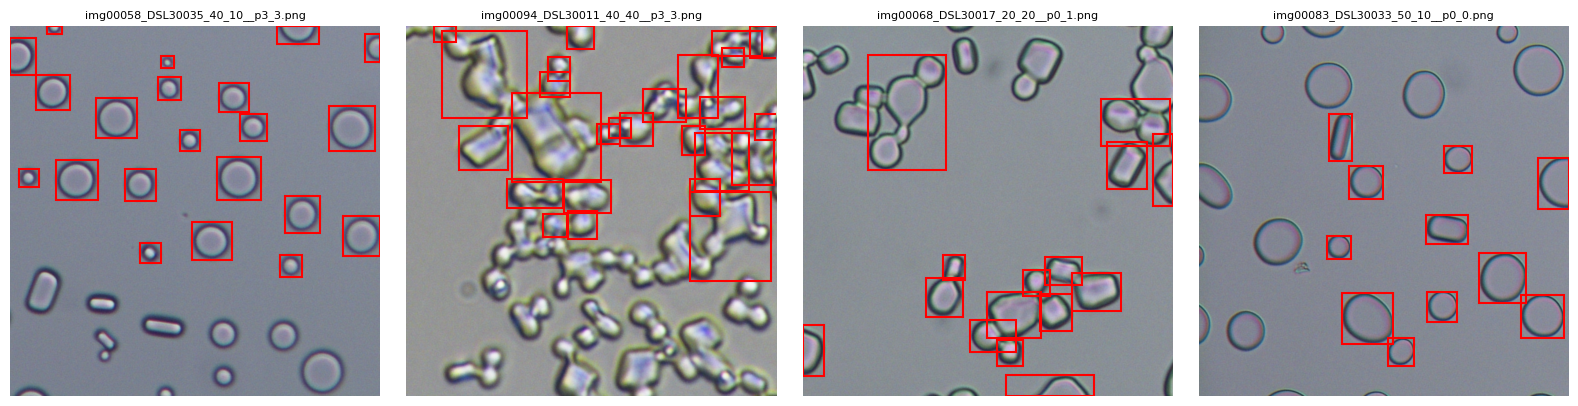

In [5]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

train_img_dir = os.path.join(YOLO_ROOT, "images", "train")
train_lbl_dir = os.path.join(YOLO_ROOT, "labels", "train")

sample_files = random.sample(os.listdir(train_img_dir), min(4, len(os.listdir(train_img_dir))))

fig, axes = plt.subplots(1, len(sample_files), figsize=(4 * len(sample_files), 4))
if len(sample_files) == 1:
    axes = [axes]
for ax, fname in zip(axes, sample_files):
    img = Image.open(os.path.join(train_img_dir, fname))
    ax.imshow(img)
    W, H = img.size
    label_path = os.path.join(train_lbl_dir, fname.rsplit(".", 1)[0] + ".txt")
    with open(label_path) as f:
        for line in f:
            _, xc, yc, bw, bh = map(float, line.split())
            x1 = (xc - bw / 2) * W
            y1 = (yc - bh / 2) * H
            ax.add_patch(mpatches.Rectangle((x1, y1), bw * W, bh * H,
                                             fill=False, edgecolor="red", linewidth=1.5))
    ax.set_title(fname, fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()